# NN Grid Research

## Setup

In [8]:
import os
os.environ["KERAS_BACKEND"] = "torch"

%load_ext autoreload
%autoreload 2

import json
import time
import matplotlib.pyplot as plt
import nnodely
import numpy as np
import pandas as pd
import time

print(f"nnodely version: {nnodely.__version__}")
print(f"Backend used: {os.environ.get('KERAS_BACKEND')}")
print("Setup completed!")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
nnodely version: 2.0.0
Backend used: torch
Setup completed!


## LUT Upload

In [2]:
from src.lut import LUT

LUT_PATH = "models/W=0.2/comb_lut_W=0.2.nc"

my_lut = LUT(LUT_PATH)
my_lut.load_data()

Dataset LUT uploaded!
LUT matrix dimension: (1147, 6)


## Grid Search Algorithm
This section trains several models and saves it into a list.
The cell execute every combination.

This section takes several minutes to be computed.

Grid Search: 15 combinations...

TRAINING: 1 Layer, 2 Neurons
Architecture of the NN: 1 layers of 2 neurons each.


Model: "nn_lut_W=0.2_1L_2U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow133     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract134         │ (None, 1, 1)      │          0 │ SampleWindow133[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[13][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide135           │ (None, 1, 1)      │          0 │ Subtract134[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[13][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow137     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate136      │ (None, 2, 1)      │          0 │ Divide135[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow137[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear139           │ (None, 2, 1)      │          6 │ Concatenate136[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU138 (ReLU)      │ (None, 2, 1)      │          0 │ Linear139[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear140           │ (None, 6, 1)      │         18 │ ReLU138[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow142     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Clamp141            │ (None, 6, 1)      │          0 │ Linear140[0][0]   │
│ (ClampImpl)         │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 26 (104.00 B)

 Trainable params: 24 (96.00 B)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_1L_2U_|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |     0.35|    -    |   0.3499|    -    |
|   8/80   |   0.2393|    -    |   0.2393|    -    |
|  12/80   |   0.1754|    -    |   0.1754|    -    |
|  16/80   |   0.1403|    -    |   0.1403|    -    |
|  20/80   |   0.1219|    -    |   0.1218|    -    |
|  24/80   |   0.1122|    -    |   0.1121|    -    |
|  28/80   |   0.1058|    -    |   0.1059|    -    |
|  32/80   |   0.1015|    -    |   0.1014|    -    |
|  36/80   |  0.09785|    -    |  0.09785|    -    |
|  40/80   |  0.09476|    -    |   0.0947|    -    |
|  44/80   |  0.09181|    -    |   0.0918|    -    |
|  48/80   |  0.08902|    -    |  0.08894|    -    |
|  52/80   |   0.0861|    -    |  0.

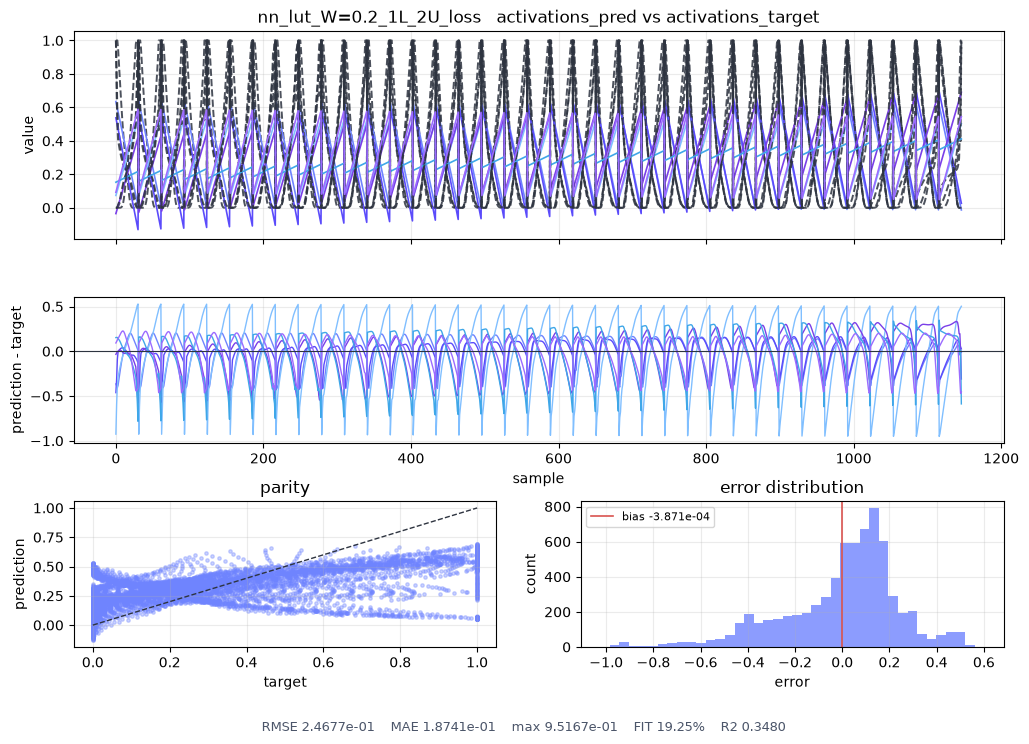

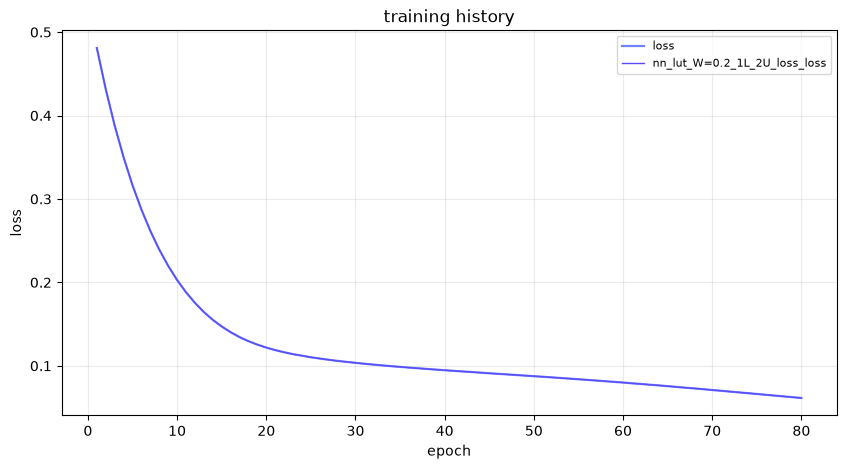

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_1L_2U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_1L_2U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   6.089348e-02
  RMSE                        2.467660e-01
  MAE                         1.874050e-01
  Max error                   9.516737e-01
  Bias (mean error)           -3.871299e-04
  Error std                   2.467657e-01
  NRMSE (% of range)          24.677 %
  FIT (% variance)            19.252 %
  R2                          0.347972
  Correlation                 0.595643
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_1L_2U\nn_lut_W_0_2_1L_2U_nn_lut_W_0_2_1L_2U_loss.png
  Figure:                     models/W

Model: "nn_lut_W=0.2_1L_4U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow143     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract144         │ (None, 1, 1)      │          0 │ SampleWindow143[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[14][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide145           │ (None, 1, 1)      │          0 │ Subtract144[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[14][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow147     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate146      │ (None, 2, 1)      │          0 │ Divide145[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow147[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear149           │ (None, 4, 1)      │         12 │ Concatenate146[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU148 (ReLU)      │ (None, 4, 1)      │          0 │ Linear149[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear150           │ (None, 6, 1)      │         30 │ ReLU148[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow152     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Clamp151            │ (None, 6, 1)      │          0 │ Linear150[0][0]   │
│ (ClampImpl)         │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 44 (176.00 B)

 Trainable params: 42 (168.00 B)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_1L_4U_|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |   0.2692|    -    |   0.2691|    -    |
|   8/80   |   0.1561|    -    |   0.1561|    -    |
|  12/80   |  0.09844|    -    |  0.09847|    -    |
|  16/80   |  0.07128|    -    |  0.07128|    -    |
|  20/80   |  0.05332|    -    |  0.05332|    -    |
|  24/80   |  0.03904|    -    |  0.03901|    -    |
|  28/80   |  0.02856|    -    |  0.02859|    -    |
|  32/80   |  0.02217|    -    |  0.02215|    -    |
|  36/80   |  0.01865|    -    |  0.01864|    -    |
|  40/80   |  0.01676|    -    |  0.01676|    -    |
|  44/80   |  0.01565|    -    |  0.01567|    -    |
|  48/80   |  0.01496|    -    |  0.01495|    -    |
|  52/80   |  0.01445|    -    |  0.

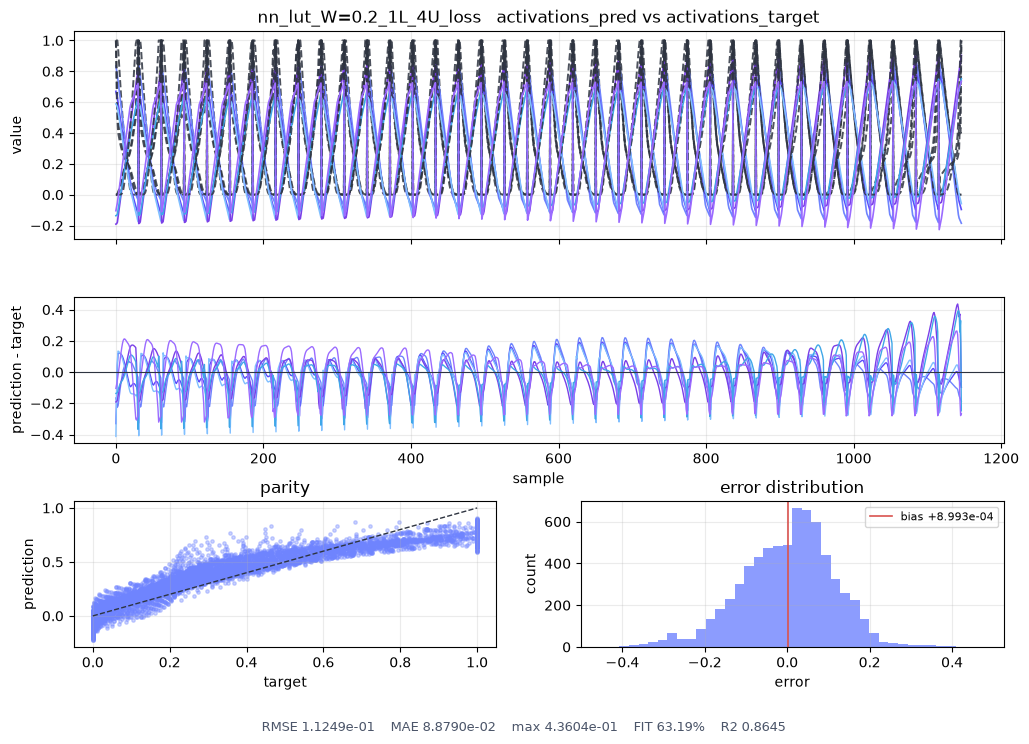

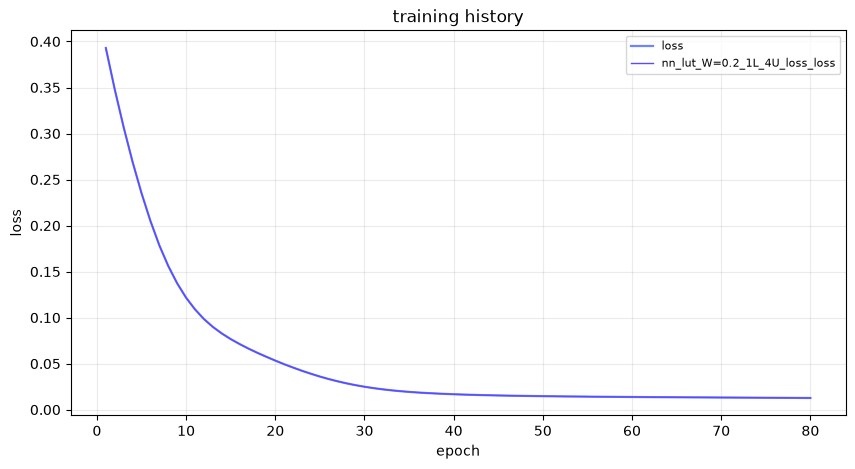

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_1L_4U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_1L_4U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   1.265343e-02
  RMSE                        1.124874e-01
  MAE                         8.879040e-02
  Max error                   4.360435e-01
  Bias (mean error)           +8.993174e-04
  Error std                   1.124838e-01
  NRMSE (% of range)          11.249 %
  FIT (% variance)            63.191 %
  R2                          0.864511
  Correlation                 0.929799
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_1L_4U\nn_lut_W_0_2_1L_4U_nn_lut_W_0_2_1L_4U_loss.png
  Figure:                     models/W

Model: "nn_lut_W=0.2_1L_8U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow153     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract154         │ (None, 1, 1)      │          0 │ SampleWindow153[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[15][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide155           │ (None, 1, 1)      │          0 │ Subtract154[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[15][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow157     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate156      │ (None, 2, 1)      │          0 │ Divide155[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow157[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear159           │ (None, 8, 1)      │         24 │ Concatenate156[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU158 (ReLU)      │ (None, 8, 1)      │          0 │ Linear159[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear160           │ (None, 6, 1)      │         54 │ ReLU158[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow162     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Clamp161            │ (None, 6, 1)      │          0 │ Linear160[0][0]   │
│ (ClampImpl)         │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 80 (320.00 B)

 Trainable params: 78 (312.00 B)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_1L_8U_|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |    0.317|    -    |   0.3169|    -    |
|   8/80   |   0.1613|    -    |   0.1613|    -    |
|  12/80   |   0.1074|    -    |   0.1074|    -    |
|  16/80   |  0.09027|    -    |  0.09027|    -    |
|  20/80   |  0.07636|    -    |  0.07634|    -    |
|  24/80   |  0.06396|    -    |  0.06393|    -    |
|  28/80   |  0.05287|    -    |  0.05293|    -    |
|  32/80   |  0.04355|    -    |  0.04354|    -    |
|  36/80   |  0.03593|    -    |   0.0359|    -    |
|  40/80   |  0.02992|    -    |  0.02992|    -    |
|  44/80   |  0.02533|    -    |  0.02535|    -    |
|  48/80   |  0.02188|    -    |  0.02186|    -    |
|  52/80   |  0.01923|    -    |  0.

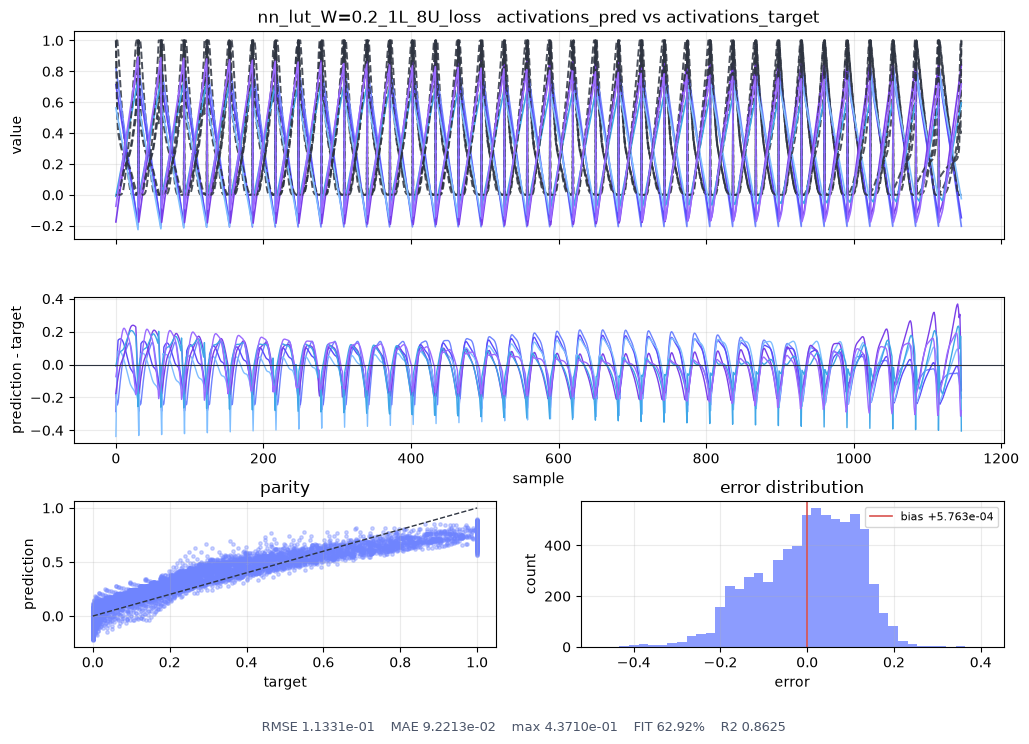

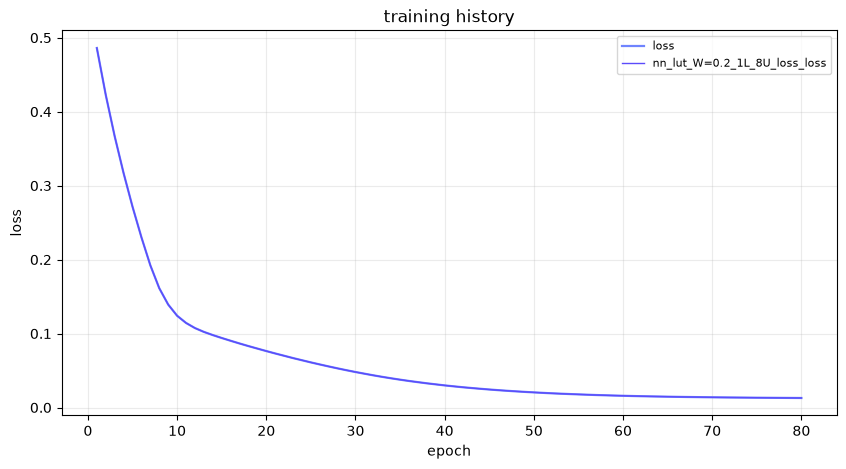

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_1L_8U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_1L_8U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   1.284002e-02
  RMSE                        1.133138e-01
  MAE                         9.221341e-02
  Max error                   4.371019e-01
  Bias (mean error)           +5.763293e-04
  Error std                   1.133124e-01
  NRMSE (% of range)          11.331 %
  FIT (% variance)            62.921 %
  R2                          0.862513
  Correlation                 0.928919
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_1L_8U\nn_lut_W_0_2_1L_8U_nn_lut_W_0_2_1L_8U_loss.png
  Figure:                     models/W

Model: "nn_lut_W=0.2_1L_16U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow163     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract164         │ (None, 1, 1)      │          0 │ SampleWindow163[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[16][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide165           │ (None, 1, 1)      │          0 │ Subtract164[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[16][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow167     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate166      │ (None, 2, 1)      │          0 │ Divide165[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow167[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear169           │ (None, 16, 1)     │         48 │ Concatenate166[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU168 (ReLU)      │ (None, 16, 1)     │          0 │ Linear169[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear170           │ (None, 6, 1)      │        102 │ ReLU168[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow172     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Clamp171            │ (None, 6, 1)      │          0 │ Linear170[0][0]   │
│ (ClampImpl)         │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 152 (608.00 B)

 Trainable params: 150 (600.00 B)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_1L_16U|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |   0.1679|    -    |   0.1679|    -    |
|   8/80   |  0.04075|    -    |  0.04075|    -    |
|  12/80   |  0.02172|    -    |  0.02172|    -    |
|  16/80   |  0.01463|    -    |  0.01463|    -    |
|  20/80   |  0.01167|    -    |  0.01167|    -    |
|  24/80   |  0.01009|    -    |  0.01007|    -    |
|  28/80   |  0.00897|    -    |  0.00898|    -    |
|  32/80   | 0.008102|    -    |   0.0081|    -    |
|  36/80   | 0.007398|    -    | 0.007392|    -    |
|  40/80   | 0.006828|    -    |  0.00683|    -    |
|  44/80   | 0.006362|    -    | 0.006371|    -    |
|  48/80   | 0.006003|    -    |    0.006|    -    |
|  52/80   | 0.005716|    -    | 0.0

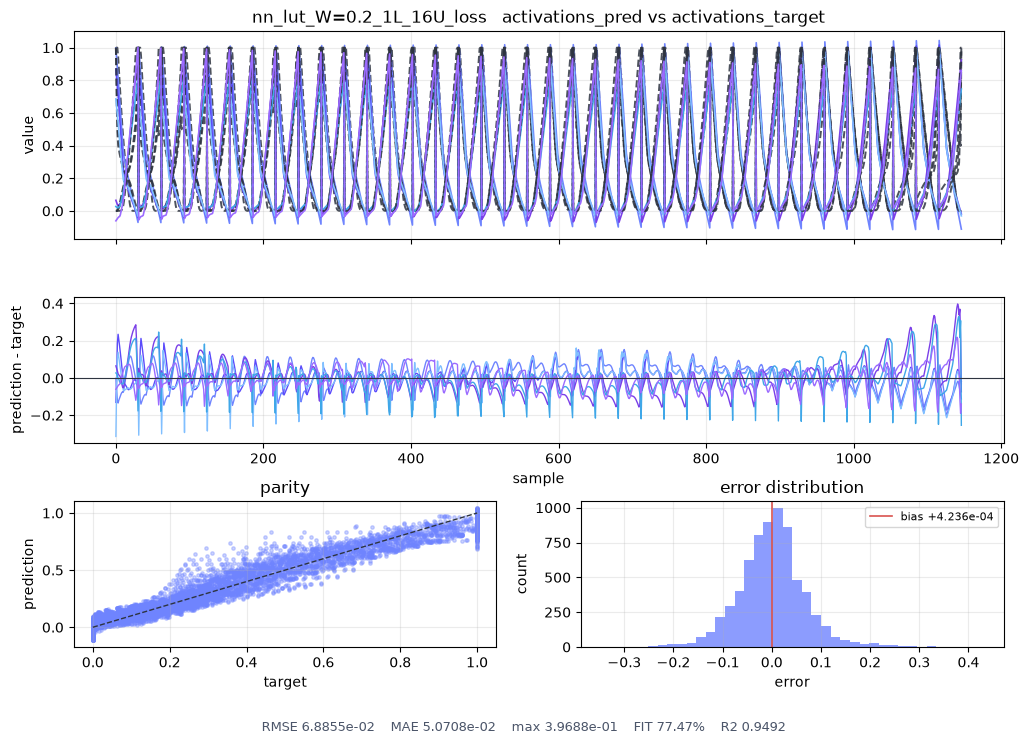

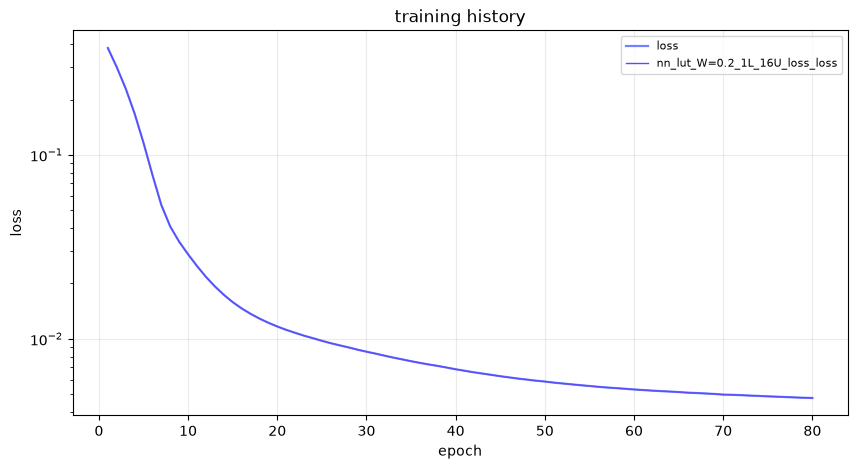

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_1L_16U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_1L_16U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   4.740997e-03
  RMSE                        6.885490e-02
  MAE                         5.070793e-02
  Max error                   3.968798e-01
  Bias (mean error)           +4.235901e-04
  Error std                   6.885360e-02
  NRMSE (% of range)          6.885 %
  FIT (% variance)            77.469 %
  R2                          0.949235
  Correlation                 0.974314
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_1L_16U\nn_lut_W_0_2_1L_16U_nn_lut_W_0_2_1L_16U_loss.png
  Figure:                     mode

Model: "nn_lut_W=0.2_1L_32U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow173     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract174         │ (None, 1, 1)      │          0 │ SampleWindow173[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[17][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide175           │ (None, 1, 1)      │          0 │ Subtract174[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[17][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow177     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate176      │ (None, 2, 1)      │          0 │ Divide175[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow177[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear179           │ (None, 32, 1)     │         96 │ Concatenate176[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU178 (ReLU)      │ (None, 32, 1)     │          0 │ Linear179[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear180           │ (None, 6, 1)      │        198 │ ReLU178[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow182     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Clamp181            │ (None, 6, 1)      │          0 │ Linear180[0][0]   │
│ (ClampImpl)         │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 296 (1.16 KB)

 Trainable params: 294 (1.15 KB)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_1L_32U|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |   0.1065|    -    |   0.1065|    -    |
|   8/80   |  0.02735|    -    |  0.02735|    -    |
|  12/80   |  0.01661|    -    |  0.01661|    -    |
|  16/80   |  0.01335|    -    |  0.01336|    -    |
|  20/80   |  0.01221|    -    |  0.01221|    -    |
|  24/80   |   0.0116|    -    |  0.01159|    -    |
|  28/80   |  0.01103|    -    |  0.01104|    -    |
|  32/80   |  0.01031|    -    |  0.01031|    -    |
|  36/80   | 0.009521|    -    | 0.009516|    -    |
|  40/80   | 0.008644|    -    | 0.008645|    -    |
|  44/80   | 0.007791|    -    | 0.007797|    -    |
|  48/80   | 0.007069|    -    | 0.007067|    -    |
|  52/80   | 0.006445|    -    | 0.0

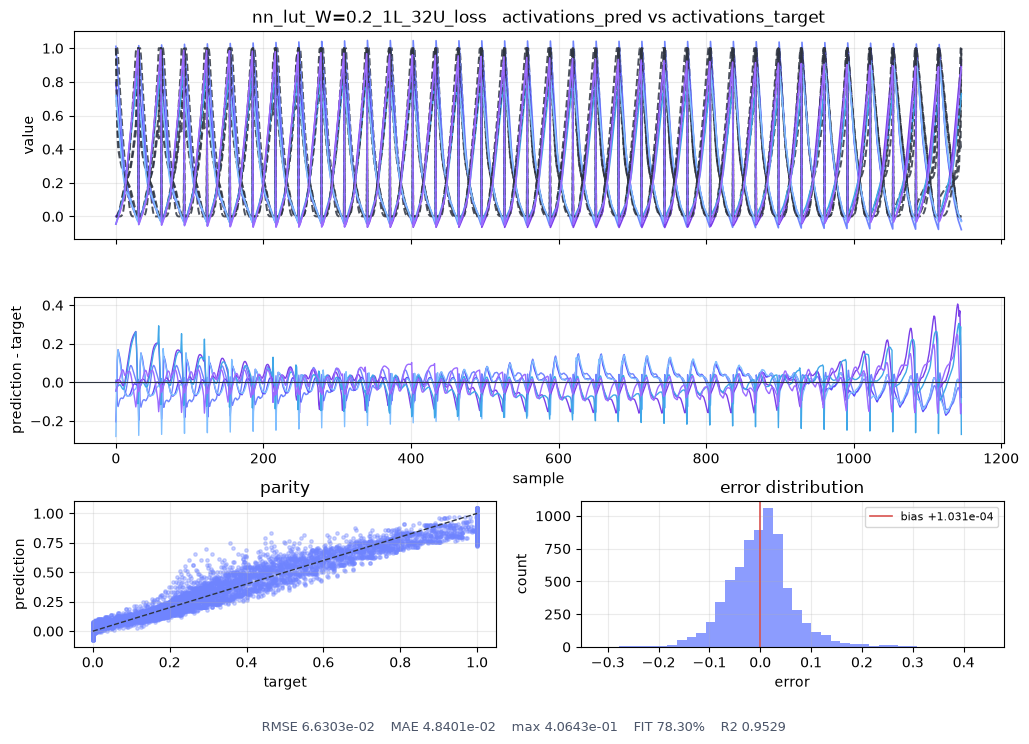

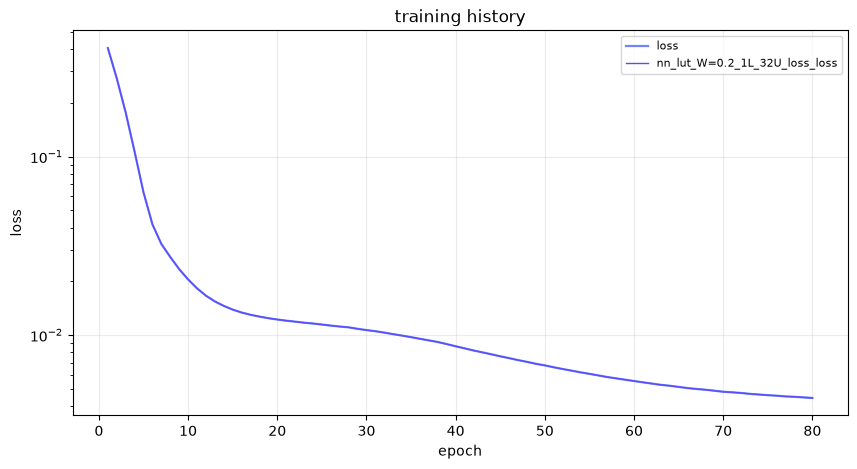

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_1L_32U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_1L_32U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   4.396042e-03
  RMSE                        6.630266e-02
  MAE                         4.840122e-02
  Max error                   4.064327e-01
  Bias (mean error)           +1.030635e-04
  Error std                   6.630258e-02
  NRMSE (% of range)          6.630 %
  FIT (% variance)            78.304 %
  R2                          0.952929
  Correlation                 0.976263
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_1L_32U\nn_lut_W_0_2_1L_32U_nn_lut_W_0_2_1L_32U_loss.png
  Figure:                     mode

Model: "nn_lut_W=0.2_2L_2U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow183     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract184         │ (None, 1, 1)      │          0 │ SampleWindow183[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[18][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide185           │ (None, 1, 1)      │          0 │ Subtract184[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[18][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow187     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate186      │ (None, 2, 1)      │          0 │ Divide185[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow187[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear189           │ (None, 2, 1)      │          6 │ Concatenate186[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU188 (ReLU)      │ (None, 2, 1)      │          0 │ Linear189[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear191           │ (None, 2, 1)      │          6 │ ReLU188[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU190 (ReLU)      │ (None, 2, 1)      │          0 │ Linear191[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear192           │ (None, 6, 1)      │         18 │ ReLU190[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow194     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Clamp193            │ (None, 6, 1)      │          0 │ Linear192[0][0]   │
│ (ClampImpl)         │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 32 (128.00 B)

 Trainable params: 30 (120.00 B)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_2L_2U_|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |    0.274|    -    |   0.2738|    -    |
|   8/80   |   0.2102|    -    |   0.2102|    -    |
|  12/80   |   0.1612|    -    |   0.1612|    -    |
|  16/80   |    0.127|    -    |    0.127|    -    |
|  20/80   |   0.1038|    -    |   0.1037|    -    |
|  24/80   |  0.08754|    -    |  0.08753|    -    |
|  28/80   |  0.07592|    -    |  0.07601|    -    |
|  32/80   |  0.06775|    -    |  0.06777|    -    |
|  36/80   |  0.06188|    -    |  0.06184|    -    |
|  40/80   |  0.05748|    -    |  0.05741|    -    |
|  44/80   |  0.05391|    -    |  0.05388|    -    |
|  48/80   |  0.05078|    -    |   0.0508|    -    |
|  52/80   |  0.04795|    -    |  0.

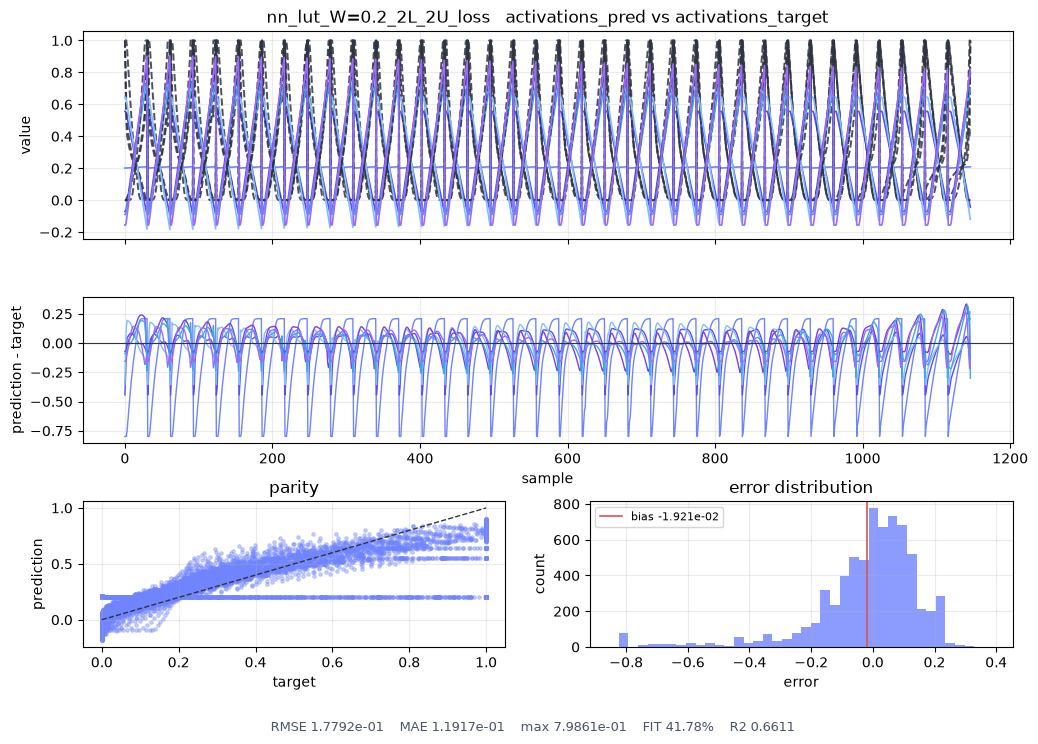

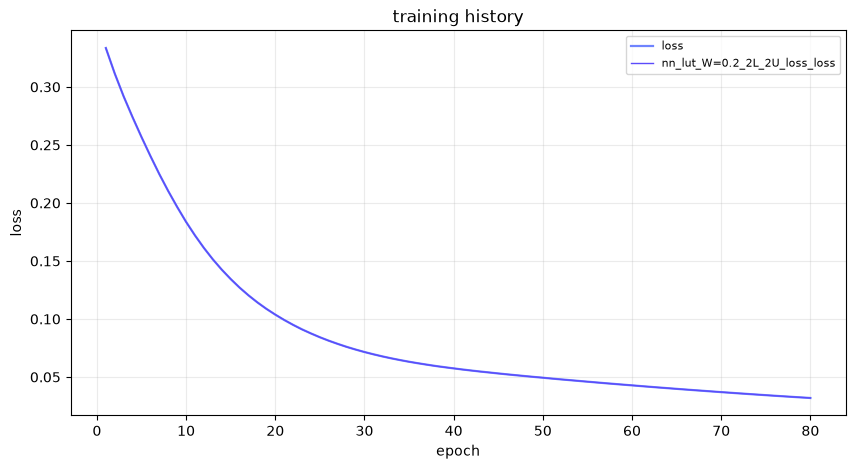

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_2L_2U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_2L_2U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   3.165416e-02
  RMSE                        1.779162e-01
  MAE                         1.191714e-01
  Max error                   7.986125e-01
  Bias (mean error)           -1.920805e-02
  Error std                   1.768763e-01
  NRMSE (% of range)          17.792 %
  FIT (% variance)            41.781 %
  R2                          0.661057
  Correlation                 0.815485
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_2L_2U\nn_lut_W_0_2_2L_2U_nn_lut_W_0_2_2L_2U_loss.png
  Figure:                     models/W

Model: "nn_lut_W=0.2_2L_4U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow195     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract196         │ (None, 1, 1)      │          0 │ SampleWindow195[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[19][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide197           │ (None, 1, 1)      │          0 │ Subtract196[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[19][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow199     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate198      │ (None, 2, 1)      │          0 │ Divide197[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow199[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear201           │ (None, 4, 1)      │         12 │ Concatenate198[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU200 (ReLU)      │ (None, 4, 1)      │          0 │ Linear201[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear203           │ (None, 4, 1)      │         20 │ ReLU200[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU202 (ReLU)      │ (None, 4, 1)      │          0 │ Linear203[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear204           │ (None, 6, 1)      │         30 │ ReLU202[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow206     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Clamp205            │ (None, 6, 1)      │          0 │ Linear204[0][0]   │
│ (ClampImpl)         │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 64 (256.00 B)

 Trainable params: 62 (248.00 B)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_2L_4U_|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |   0.3009|    -    |   0.3007|    -    |
|   8/80   |   0.2543|    -    |   0.2543|    -    |
|  12/80   |   0.2185|    -    |   0.2185|    -    |
|  16/80   |   0.1904|    -    |   0.1904|    -    |
|  20/80   |   0.1683|    -    |   0.1683|    -    |
|  24/80   |   0.1509|    -    |   0.1509|    -    |
|  28/80   |   0.1371|    -    |   0.1373|    -    |
|  32/80   |   0.1266|    -    |   0.1266|    -    |
|  36/80   |   0.1184|    -    |   0.1183|    -    |
|  40/80   |    0.112|    -    |   0.1119|    -    |
|  44/80   |    0.107|    -    |    0.107|    -    |
|  48/80   |   0.1033|    -    |   0.1032|    -    |
|  52/80   |   0.1004|    -    |   0

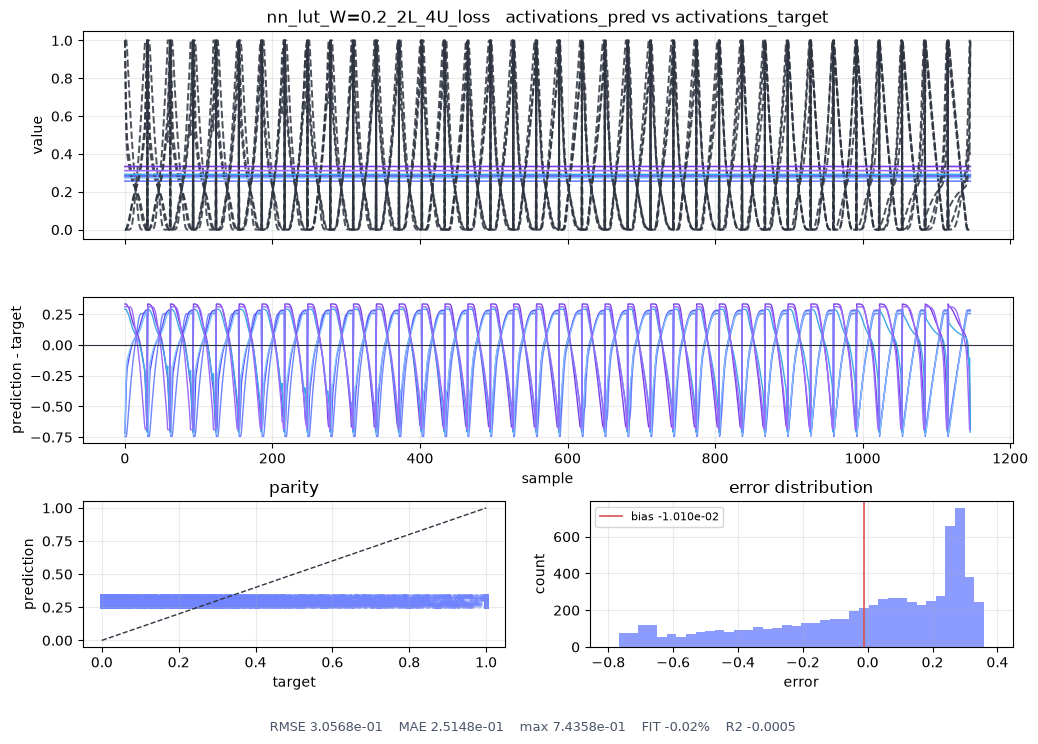

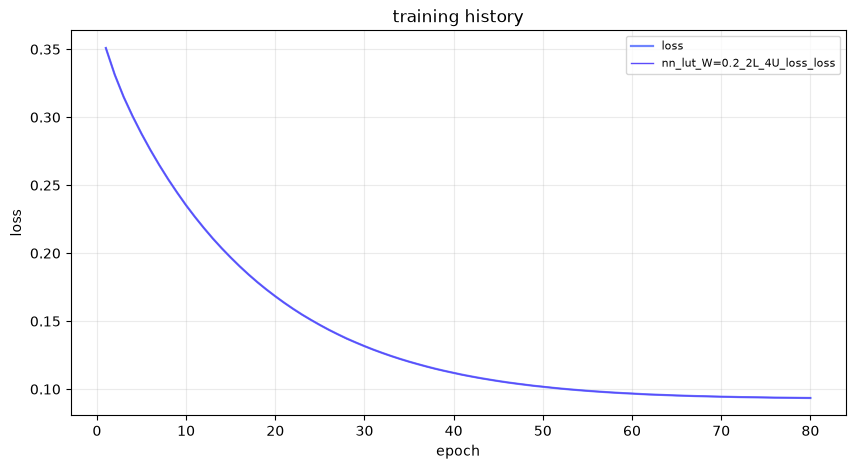

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_2L_4U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_2L_4U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   9.343740e-02
  RMSE                        3.056753e-01
  MAE                         2.514765e-01
  Max error                   7.435844e-01
  Bias (mean error)           -1.010208e-02
  Error std                   3.055083e-01
  NRMSE (% of range)          30.568 %
  FIT (% variance)            -0.025 %
  R2                          -0.000498
  Correlation                 0.044797
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_2L_4U\nn_lut_W_0_2_2L_4U_nn_lut_W_0_2_2L_4U_loss.png
  Figure:                     models/

Model: "nn_lut_W=0.2_2L_8U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow207     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract208         │ (None, 1, 1)      │          0 │ SampleWindow207[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[20][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide209           │ (None, 1, 1)      │          0 │ Subtract208[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[20][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow211     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate210      │ (None, 2, 1)      │          0 │ Divide209[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow211[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear213           │ (None, 8, 1)      │         24 │ Concatenate210[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU212 (ReLU)      │ (None, 8, 1)      │          0 │ Linear213[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear215           │ (None, 8, 1)      │         72 │ ReLU212[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU214 (ReLU)      │ (None, 8, 1)      │          0 │ Linear215[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear216           │ (None, 6, 1)      │         54 │ ReLU214[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow218     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Clamp217            │ (None, 6, 1)      │          0 │ Linear216[0][0]   │
│ (ClampImpl)         │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 152 (608.00 B)

 Trainable params: 150 (600.00 B)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_2L_8U_|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |   0.2568|    -    |   0.2568|    -    |
|   8/80   |   0.1012|    -    |   0.1012|    -    |
|  12/80   |  0.05417|    -    |  0.05416|    -    |
|  16/80   |  0.03822|    -    |  0.03823|    -    |
|  20/80   |  0.02795|    -    |  0.02793|    -    |
|  24/80   |  0.02075|    -    |  0.02074|    -    |
|  28/80   |  0.01584|    -    |  0.01585|    -    |
|  32/80   |  0.01262|    -    |  0.01263|    -    |
|  36/80   |  0.01058|    -    |  0.01057|    -    |
|  40/80   | 0.009289|    -    | 0.009287|    -    |
|  44/80   | 0.008449|    -    | 0.008453|    -    |
|  48/80   | 0.007877|    -    | 0.007876|    -    |
|  52/80   | 0.007447|    -    | 0.0

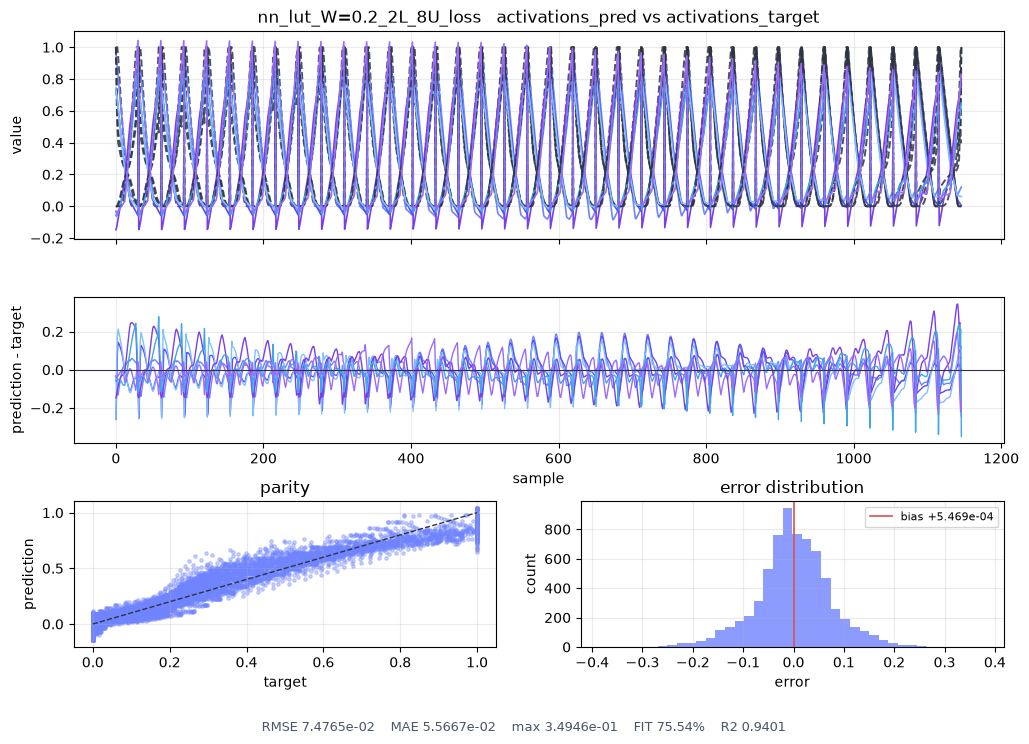

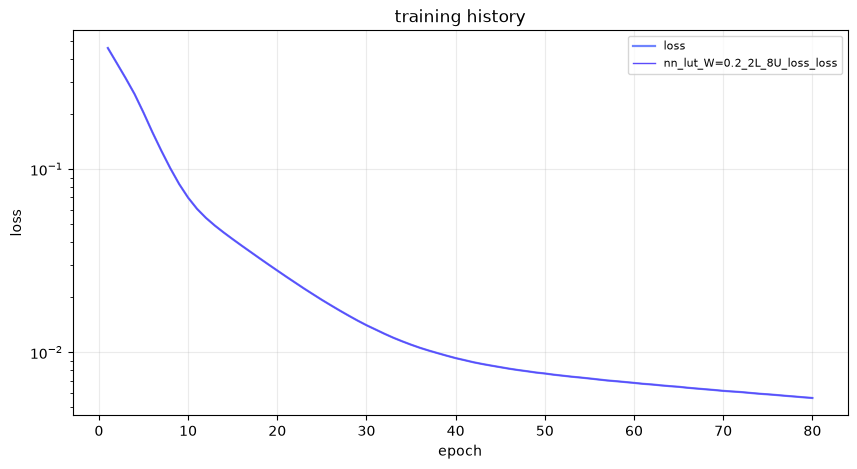

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_2L_8U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_2L_8U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   5.589754e-03
  RMSE                        7.476466e-02
  MAE                         5.566698e-02
  Max error                   3.494582e-01
  Bias (mean error)           +5.469158e-04
  Error std                   7.476266e-02
  NRMSE (% of range)          7.476 %
  FIT (% variance)            75.535 %
  R2                          0.940147
  Correlation                 0.969650
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_2L_8U\nn_lut_W_0_2_2L_8U_nn_lut_W_0_2_2L_8U_loss.png
  Figure:                     models/W=

Model: "nn_lut_W=0.2_2L_16U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow219     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract220         │ (None, 1, 1)      │          0 │ SampleWindow219[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[21][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide221           │ (None, 1, 1)      │          0 │ Subtract220[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[21][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow223     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate222      │ (None, 2, 1)      │          0 │ Divide221[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow223[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear225           │ (None, 16, 1)     │         48 │ Concatenate222[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU224 (ReLU)      │ (None, 16, 1)     │          0 │ Linear225[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear227           │ (None, 16, 1)     │        272 │ ReLU224[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU226 (ReLU)      │ (None, 16, 1)     │          0 │ Linear227[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear228           │ (None, 6, 1)      │        102 │ ReLU226[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow230     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Clamp229            │ (None, 6, 1)      │          0 │ Linear228[0][0]   │
│ (ClampImpl)         │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 424 (1.66 KB)

 Trainable params: 422 (1.65 KB)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_2L_16U|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |   0.1909|    -    |   0.1909|    -    |
|   8/80   |  0.06136|    -    |  0.06137|    -    |
|  12/80   |  0.03591|    -    |  0.03589|    -    |
|  16/80   |  0.01912|    -    |  0.01912|    -    |
|  20/80   |  0.01327|    -    |  0.01326|    -    |
|  24/80   |  0.01144|    -    |  0.01143|    -    |
|  28/80   |  0.01056|    -    |  0.01057|    -    |
|  32/80   | 0.009893|    -    | 0.009891|    -    |
|  36/80   | 0.009329|    -    | 0.009322|    -    |
|  40/80   | 0.008838|    -    | 0.008838|    -    |
|  44/80   | 0.008352|    -    | 0.008359|    -    |
|  48/80   | 0.007855|    -    |  0.00785|    -    |
|  52/80   | 0.007379|    -    |  0.

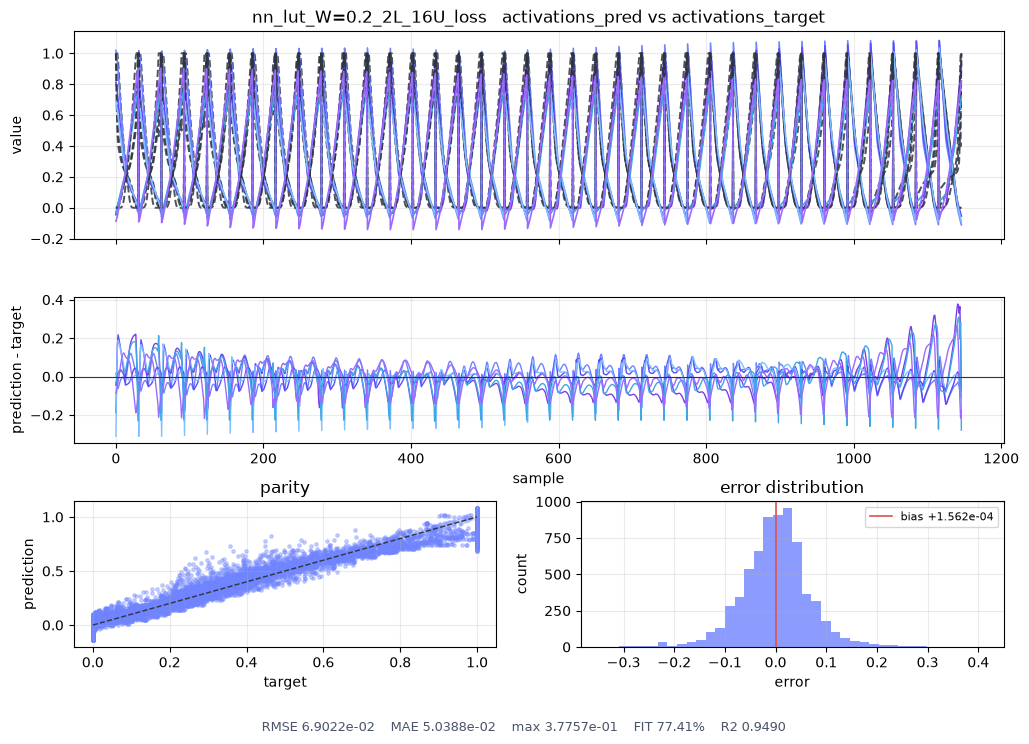

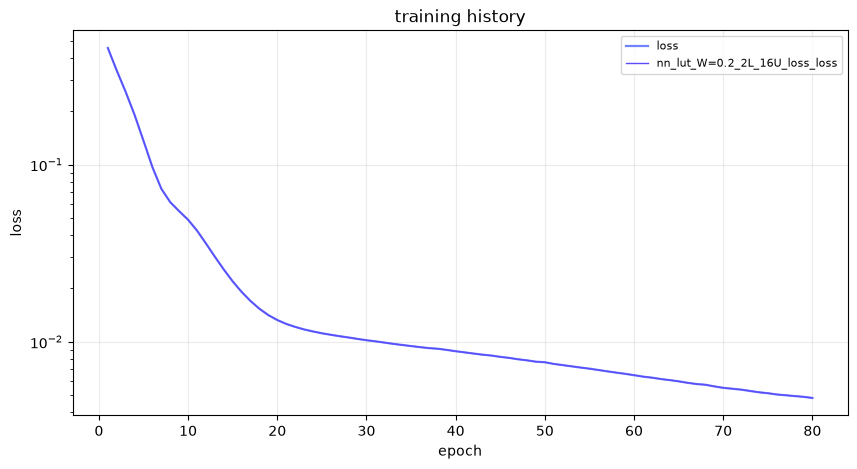

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_2L_16U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_2L_16U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   4.764053e-03
  RMSE                        6.902212e-02
  MAE                         5.038808e-02
  Max error                   3.775679e-01
  Bias (mean error)           +1.561587e-04
  Error std                   6.902194e-02
  NRMSE (% of range)          6.902 %
  FIT (% variance)            77.414 %
  R2                          0.948988
  Correlation                 0.974212
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_2L_16U\nn_lut_W_0_2_2L_16U_nn_lut_W_0_2_2L_16U_loss.png
  Figure:                     mode

Model: "nn_lut_W=0.2_2L_32U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow231     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract232         │ (None, 1, 1)      │          0 │ SampleWindow231[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[22][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide233           │ (None, 1, 1)      │          0 │ Subtract232[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[22][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow235     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate234      │ (None, 2, 1)      │          0 │ Divide233[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow235[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear237           │ (None, 32, 1)     │         96 │ Concatenate234[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU236 (ReLU)      │ (None, 32, 1)     │          0 │ Linear237[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear239           │ (None, 32, 1)     │      1,056 │ ReLU236[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU238 (ReLU)      │ (None, 32, 1)     │          0 │ Linear239[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear240           │ (None, 6, 1)      │        198 │ ReLU238[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow242     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Clamp241            │ (None, 6, 1)      │          0 │ Linear240[0][0]   │
│ (ClampImpl)         │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,352 (5.28 KB)

 Trainable params: 1,350 (5.27 KB)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_2L_32U|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |  0.05917|    -    |   0.0591|    -    |
|   8/80   |  0.01391|    -    |  0.01391|    -    |
|  12/80   | 0.009555|    -    | 0.009559|    -    |
|  16/80   | 0.007915|    -    | 0.007921|    -    |
|  20/80   | 0.006532|    -    | 0.006532|    -    |
|  24/80   |  0.00538|    -    | 0.005371|    -    |
|  28/80   | 0.004525|    -    | 0.004528|    -    |
|  32/80   | 0.003921|    -    | 0.003921|    -    |
|  36/80   |  0.00341|    -    | 0.003408|    -    |
|  40/80   | 0.003008|    -    | 0.003009|    -    |
|  44/80   | 0.002736|    -    | 0.002741|    -    |
|  48/80   | 0.002526|    -    | 0.002525|    -    |
|  52/80   | 0.002344|    -    | 0.0

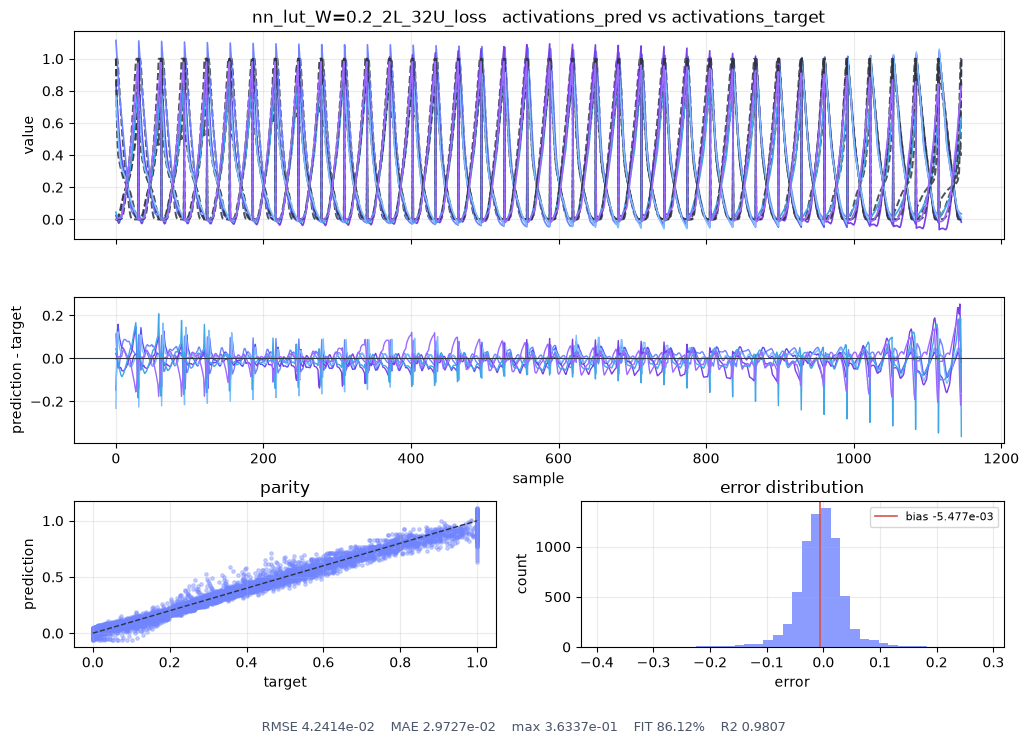

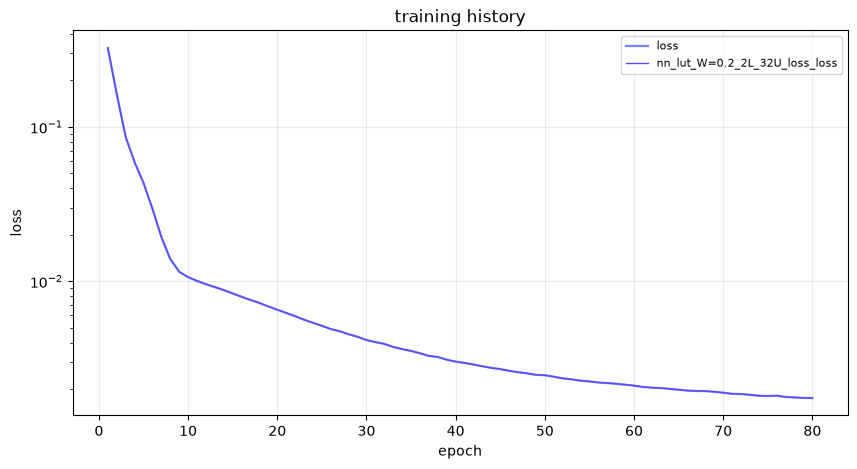

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_2L_32U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_2L_32U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   1.798986e-03
  RMSE                        4.241446e-02
  MAE                         2.972710e-02
  Max error                   3.633725e-01
  Bias (mean error)           -5.476985e-03
  Error std                   4.205935e-02
  NRMSE (% of range)          4.241 %
  FIT (% variance)            86.121 %
  R2                          0.980737
  Correlation                 0.990510
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_2L_32U\nn_lut_W_0_2_2L_32U_nn_lut_W_0_2_2L_32U_loss.png
  Figure:                     mode

Model: "nn_lut_W=0.2_3L_2U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow243     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract244         │ (None, 1, 1)      │          0 │ SampleWindow243[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[23][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide245           │ (None, 1, 1)      │          0 │ Subtract244[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[23][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow247     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate246      │ (None, 2, 1)      │          0 │ Divide245[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow247[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear249           │ (None, 2, 1)      │          6 │ Concatenate246[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU248 (ReLU)      │ (None, 2, 1)      │          0 │ Linear249[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear251           │ (None, 2, 1)      │          6 │ ReLU248[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU250 (ReLU)      │ (None, 2, 1)      │          0 │ Linear251[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear253           │ (None, 2, 1)      │          6 │ ReLU250[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU252 (ReLU)      │ (None, 2, 1)      │          0 │ Linear253[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear254           │ (None, 6, 1)      │         18 │ ReLU252[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow256     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                 

 Total params: 38 (152.00 B)

 Trainable params: 36 (144.00 B)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_3L_2U_|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |   0.3649|    -    |   0.3645|    -    |
|   8/80   |   0.3123|    -    |   0.3123|    -    |
|  12/80   |   0.2686|    -    |   0.2686|    -    |
|  16/80   |   0.2325|    -    |   0.2325|    -    |
|  20/80   |   0.2031|    -    |    0.203|    -    |
|  24/80   |    0.179|    -    |    0.179|    -    |
|  28/80   |   0.1596|    -    |   0.1598|    -    |
|  32/80   |   0.1444|    -    |   0.1444|    -    |
|  36/80   |   0.1323|    -    |   0.1323|    -    |
|  40/80   |   0.1229|    -    |   0.1228|    -    |
|  44/80   |   0.1154|    -    |   0.1154|    -    |
|  48/80   |   0.1097|    -    |   0.1097|    -    |
|  52/80   |   0.1053|    -    |   0

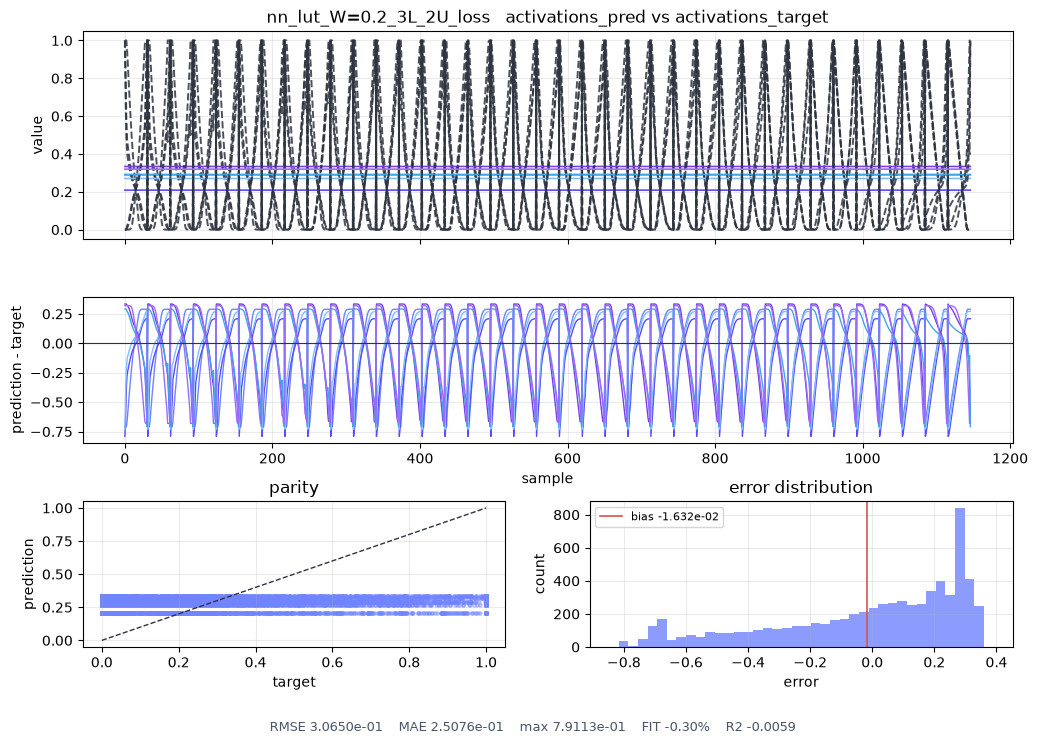

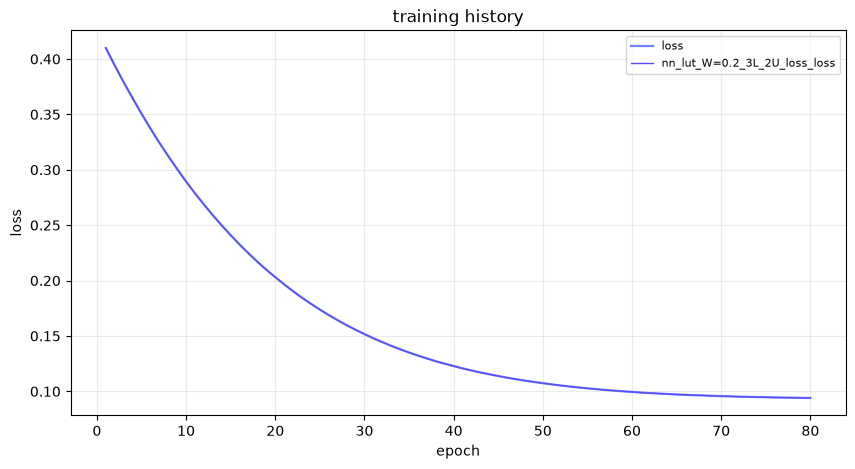

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_3L_2U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_3L_2U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   9.394502e-02
  RMSE                        3.065045e-01
  MAE                         2.507641e-01
  Max error                   7.911285e-01
  Bias (mean error)           -1.632409e-02
  Error std                   3.060695e-01
  NRMSE (% of range)          30.650 %
  FIT (% variance)            -0.296 %
  R2                          -0.005933
  Correlation                 0.053972
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_3L_2U\nn_lut_W_0_2_3L_2U_nn_lut_W_0_2_3L_2U_loss.png
  Figure:                     models/

Model: "nn_lut_W=0.2_3L_4U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow257     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract258         │ (None, 1, 1)      │          0 │ SampleWindow257[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[24][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide259           │ (None, 1, 1)      │          0 │ Subtract258[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[24][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow261     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate260      │ (None, 2, 1)      │          0 │ Divide259[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow261[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear263           │ (None, 4, 1)      │         12 │ Concatenate260[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU262 (ReLU)      │ (None, 4, 1)      │          0 │ Linear263[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear265           │ (None, 4, 1)      │         20 │ ReLU262[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU264 (ReLU)      │ (None, 4, 1)      │          0 │ Linear265[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear267           │ (None, 4, 1)      │         20 │ ReLU264[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU266 (ReLU)      │ (None, 4, 1)      │          0 │ Linear267[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear268           │ (None, 6, 1)      │         30 │ ReLU266[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow270     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                 

 Total params: 84 (336.00 B)

 Trainable params: 82 (328.00 B)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_3L_4U_|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |   0.5656|    -    |   0.5653|    -    |
|   8/80   |   0.1989|    -    |    0.199|    -    |
|  12/80   |   0.1063|    -    |   0.1063|    -    |
|  16/80   |  0.09161|    -    |  0.09161|    -    |
|  20/80   |  0.08238|    -    |  0.08236|    -    |
|  24/80   |  0.07453|    -    |  0.07451|    -    |
|  28/80   |  0.06706|    -    |  0.06713|    -    |
|  32/80   |  0.06007|    -    |  0.06003|    -    |
|  36/80   |  0.05324|    -    |  0.05323|    -    |
|  40/80   |  0.04681|    -    |  0.04681|    -    |
|  44/80   |  0.04096|    -    |  0.04099|    -    |
|  48/80   |  0.03597|    -    |   0.0359|    -    |
|  52/80   |  0.03168|    -    |  0.

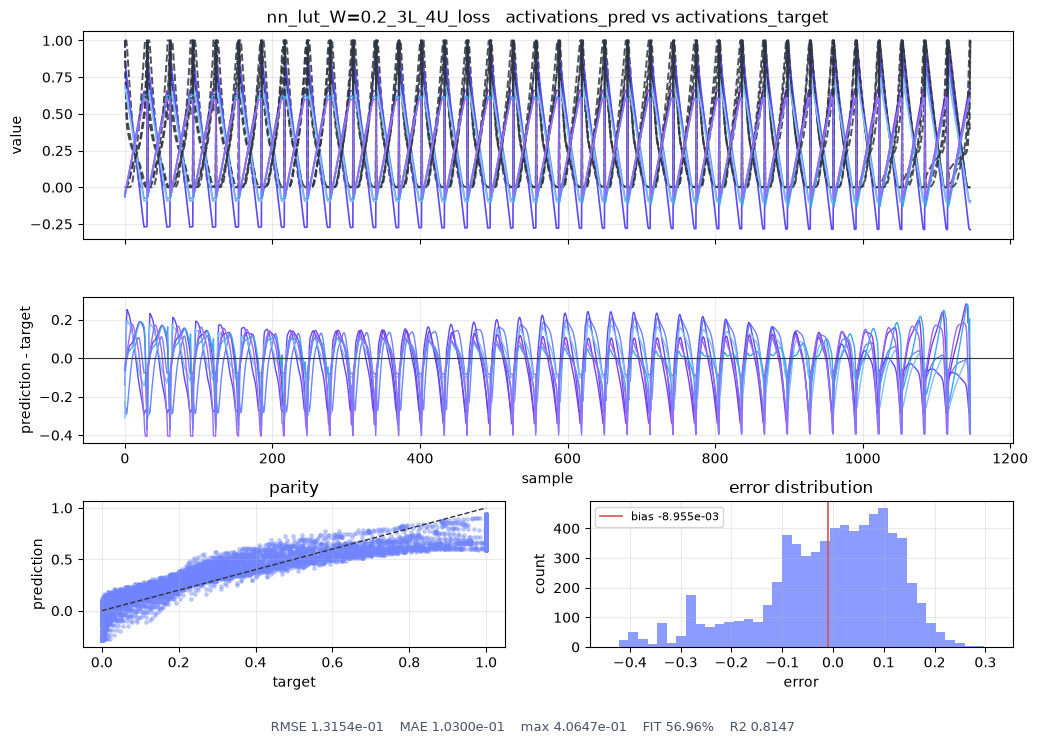

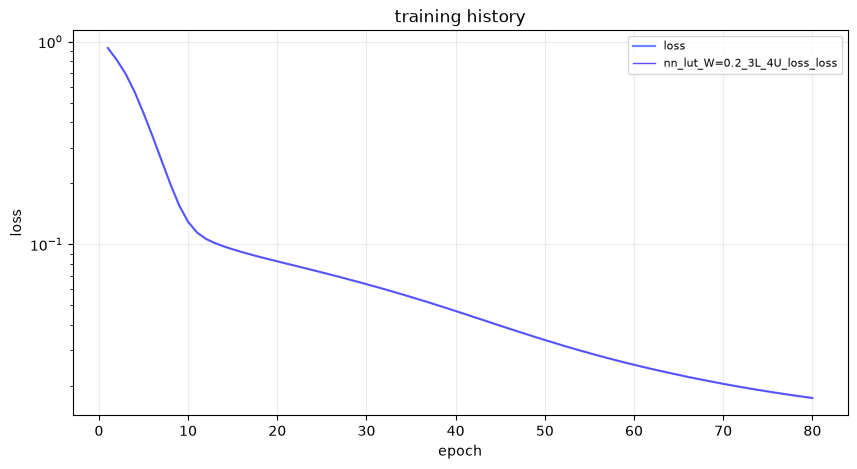

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_3L_4U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_3L_4U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   1.730404e-02
  RMSE                        1.315448e-01
  MAE                         1.029973e-01
  Max error                   4.064726e-01
  Bias (mean error)           -8.954723e-03
  Error std                   1.312397e-01
  NRMSE (% of range)          13.154 %
  FIT (% variance)            56.955 %
  R2                          0.814714
  Correlation                 0.903094
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_3L_4U\nn_lut_W_0_2_3L_4U_nn_lut_W_0_2_3L_4U_loss.png
  Figure:                     models/W

Model: "nn_lut_W=0.2_3L_8U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow271     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract272         │ (None, 1, 1)      │          0 │ SampleWindow271[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[25][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide273           │ (None, 1, 1)      │          0 │ Subtract272[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[25][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow275     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate274      │ (None, 2, 1)      │          0 │ Divide273[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow275[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear277           │ (None, 8, 1)      │         24 │ Concatenate274[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU276 (ReLU)      │ (None, 8, 1)      │          0 │ Linear277[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear279           │ (None, 8, 1)      │         72 │ ReLU276[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU278 (ReLU)      │ (None, 8, 1)      │          0 │ Linear279[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear281           │ (None, 8, 1)      │         72 │ ReLU278[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU280 (ReLU)      │ (None, 8, 1)      │          0 │ Linear281[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear282           │ (None, 6, 1)      │         54 │ ReLU280[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow284     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                 

 Total params: 224 (896.00 B)

 Trainable params: 222 (888.00 B)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_3L_8U_|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |   0.2671|    -    |   0.2668|    -    |
|   8/80   |   0.1211|    -    |   0.1211|    -    |
|  12/80   |     0.09|    -    |  0.08998|    -    |
|  16/80   |  0.07266|    -    |  0.07265|    -    |
|  20/80   |  0.05843|    -    |  0.05844|    -    |
|  24/80   |   0.0491|    -    |  0.04908|    -    |
|  28/80   |  0.04272|    -    |  0.04276|    -    |
|  32/80   |  0.03756|    -    |  0.03753|    -    |
|  36/80   |  0.03212|    -    |   0.0321|    -    |
|  40/80   |  0.02641|    -    |  0.02643|    -    |
|  44/80   |  0.02167|    -    |   0.0217|    -    |
|  48/80   |  0.01855|    -    |  0.01851|    -    |
|  52/80   |  0.01653|    -    |  0.

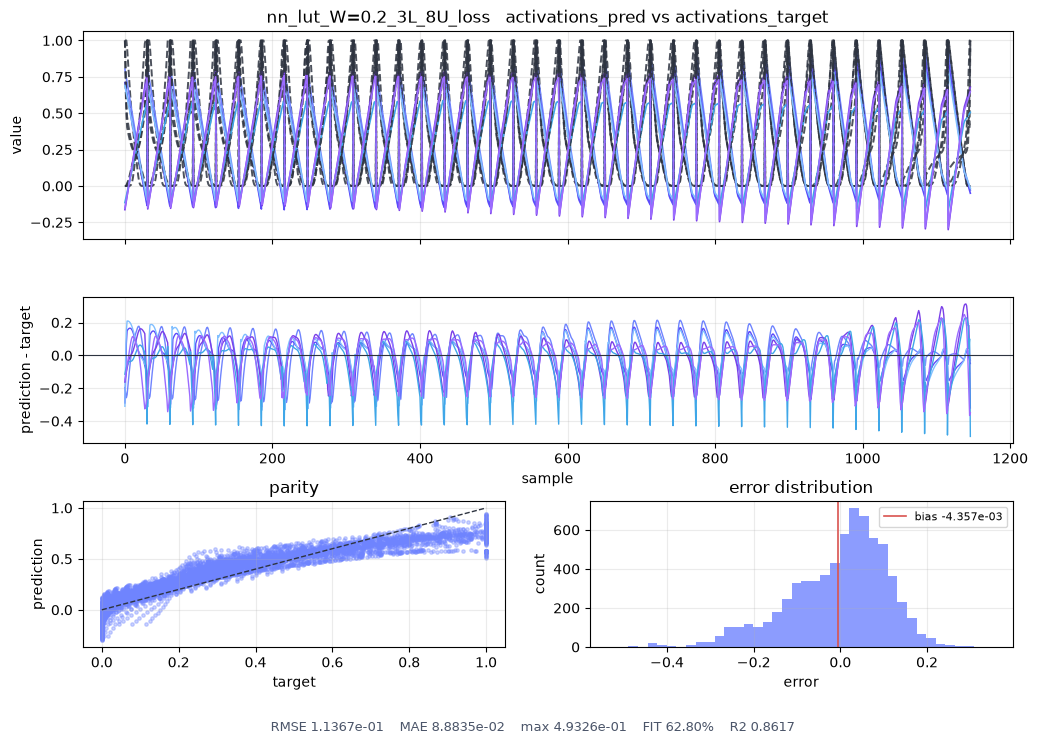

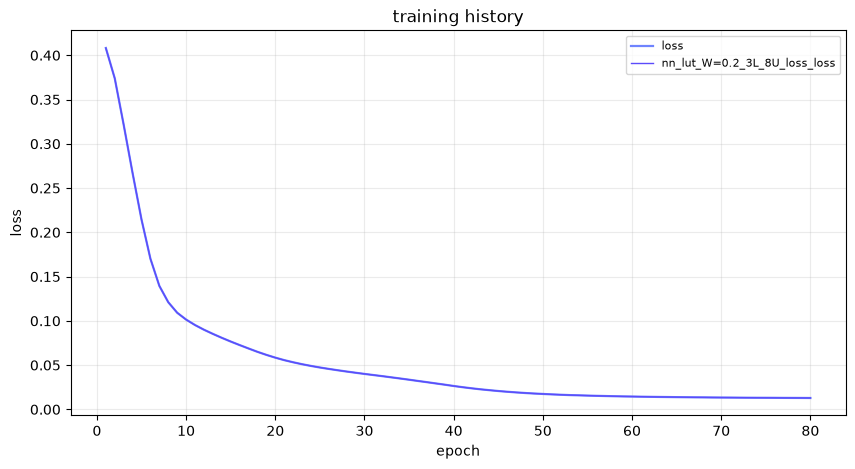

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_3L_8U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_3L_8U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   1.292044e-02
  RMSE                        1.136681e-01
  MAE                         8.883499e-02
  Max error                   4.932600e-01
  Bias (mean error)           -4.357209e-03
  Error std                   1.135846e-01
  NRMSE (% of range)          11.367 %
  FIT (% variance)            62.805 %
  R2                          0.861652
  Correlation                 0.928629
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_3L_8U\nn_lut_W_0_2_3L_8U_nn_lut_W_0_2_3L_8U_loss.png
  Figure:                     models/W

Model: "nn_lut_W=0.2_3L_16U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow285     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract286         │ (None, 1, 1)      │          0 │ SampleWindow285[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[26][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide287           │ (None, 1, 1)      │          0 │ Subtract286[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[26][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow289     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate288      │ (None, 2, 1)      │          0 │ Divide287[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow289[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear291           │ (None, 16, 1)     │         48 │ Concatenate288[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU290 (ReLU)      │ (None, 16, 1)     │          0 │ Linear291[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear293           │ (None, 16, 1)     │        272 │ ReLU290[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU292 (ReLU)      │ (None, 16, 1)     │          0 │ Linear293[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear295           │ (None, 16, 1)     │        272 │ ReLU292[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU294 (ReLU)      │ (None, 16, 1)     │          0 │ Linear295[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear296           │ (None, 6, 1)      │        102 │ ReLU294[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow298     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                 

 Total params: 696 (2.72 KB)

 Trainable params: 694 (2.71 KB)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_3L_16U|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |  0.09017|    -    |  0.09003|    -    |
|   8/80   |  0.04194|    -    |  0.04196|    -    |
|  12/80   |  0.01322|    -    |  0.01324|    -    |
|  16/80   | 0.007167|    -    | 0.007173|    -    |
|  20/80   | 0.005753|    -    | 0.005751|    -    |
|  24/80   | 0.004952|    -    | 0.004948|    -    |
|  28/80   | 0.004442|    -    | 0.004445|    -    |
|  32/80   | 0.004112|    -    | 0.004112|    -    |
|  36/80   |  0.00386|    -    | 0.003857|    -    |
|  40/80   | 0.003628|    -    | 0.003628|    -    |
|  44/80   | 0.003491|    -    | 0.003494|    -    |
|  48/80   | 0.003342|    -    | 0.003342|    -    |
|  52/80   | 0.003251|    -    | 0.0

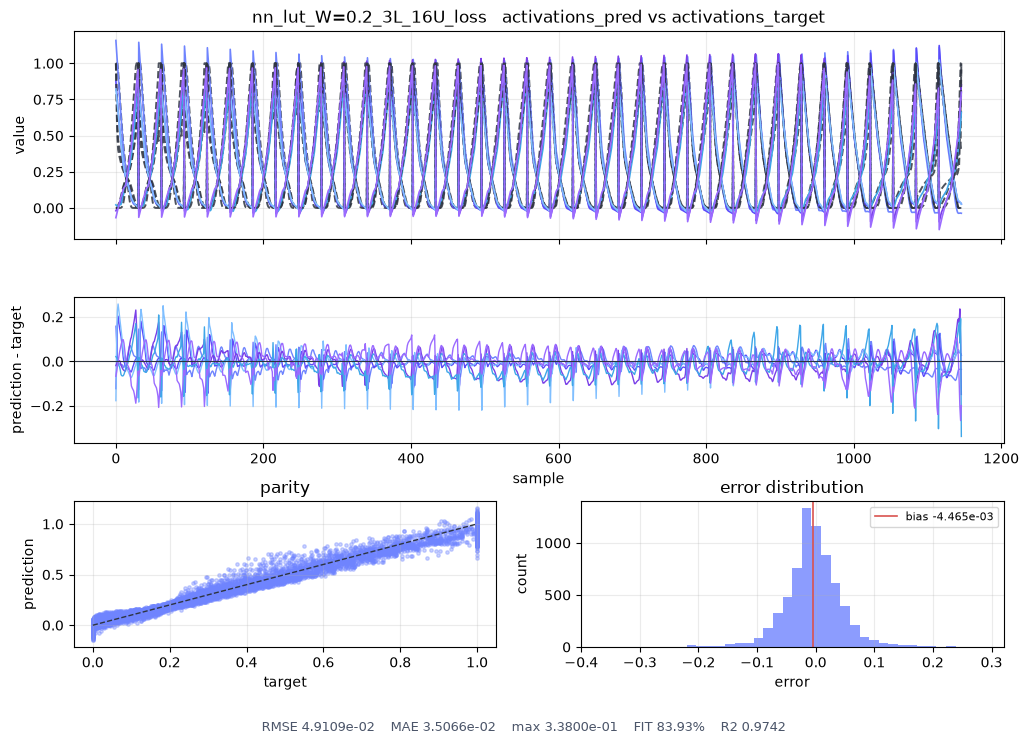

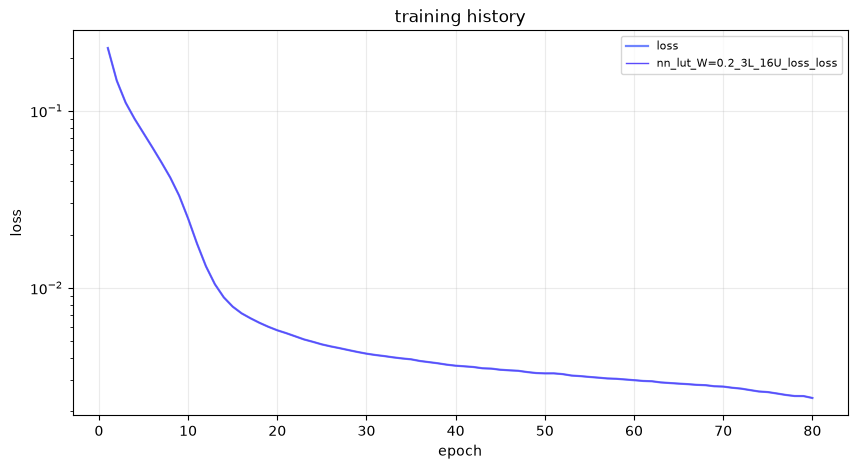

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_3L_16U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_3L_16U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   2.411715e-03
  RMSE                        4.910921e-02
  MAE                         3.506622e-02
  Max error                   3.380039e-01
  Bias (mean error)           -4.465013e-03
  Error std                   4.890581e-02
  NRMSE (% of range)          4.911 %
  FIT (% variance)            83.930 %
  R2                          0.974176
  Correlation                 0.987180
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_3L_16U\nn_lut_W_0_2_3L_16U_nn_lut_W_0_2_3L_16U_loss.png
  Figure:                     mode

Model: "nn_lut_W=0.2_3L_32U_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow299     │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract300         │ (None, 1, 1)      │          0 │ SampleWindow299[… │
│ (BinaryOpImpl)      │                   │            │ Constant3[27][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide301           │ (None, 1, 1)      │          0 │ Subtract300[0][0… │
│ (BinaryOpImpl)      │                   │            │ Constant5[27][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow303     │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate302      │ (None, 2, 1)      │          0 │ Divide301[0][0],  │
│ (ConcatenateImpl)   │                   │            │ SampleWindow303[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear305           │ (None, 32, 1)     │         96 │ Concatenate302[0… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU304 (ReLU)      │ (None, 32, 1)     │          0 │ Linear305[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear307           │ (None, 32, 1)     │      1,056 │ ReLU304[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU306 (ReLU)      │ (None, 32, 1)     │          0 │ Linear307[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear309           │ (None, 32, 1)     │      1,056 │ ReLU306[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU308 (ReLU)      │ (None, 32, 1)     │          0 │ Linear309[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear310           │ (None, 6, 1)      │        198 │ ReLU308[0][0]     │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow312     │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                 

 Total params: 2,408 (9.41 KB)

 Trainable params: 2,406 (9.40 KB)

 Non-trainable params: 2 (8.00 B)

Number of rows in the dataset: 1147
Training for 80 epochs...

================= nnodely Training =================
|  Epoch   |nn_lut_W=0.2_3L_32U|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|   4/80   |  0.05226|    -    |  0.05223|    -    |
|   8/80   |  0.01235|    -    |  0.01235|    -    |
|  12/80   |  0.01027|    -    |  0.01026|    -    |
|  16/80   | 0.008705|    -    | 0.008712|    -    |
|  20/80   | 0.007243|    -    | 0.007239|    -    |
|  24/80   | 0.005807|    -    |   0.0058|    -    |
|  28/80   | 0.004639|    -    | 0.004645|    -    |
|  32/80   | 0.003799|    -    | 0.003799|    -    |
|  36/80   |  0.00329|    -    | 0.003287|    -    |
|  40/80   | 0.002892|    -    | 0.002894|    -    |
|  44/80   | 0.002715|    -    | 0.002719|    -    |
|  48/80   |  0.00258|    -    | 0.002579|    -    |
|  52/80   | 0.002446|    -    | 0.0

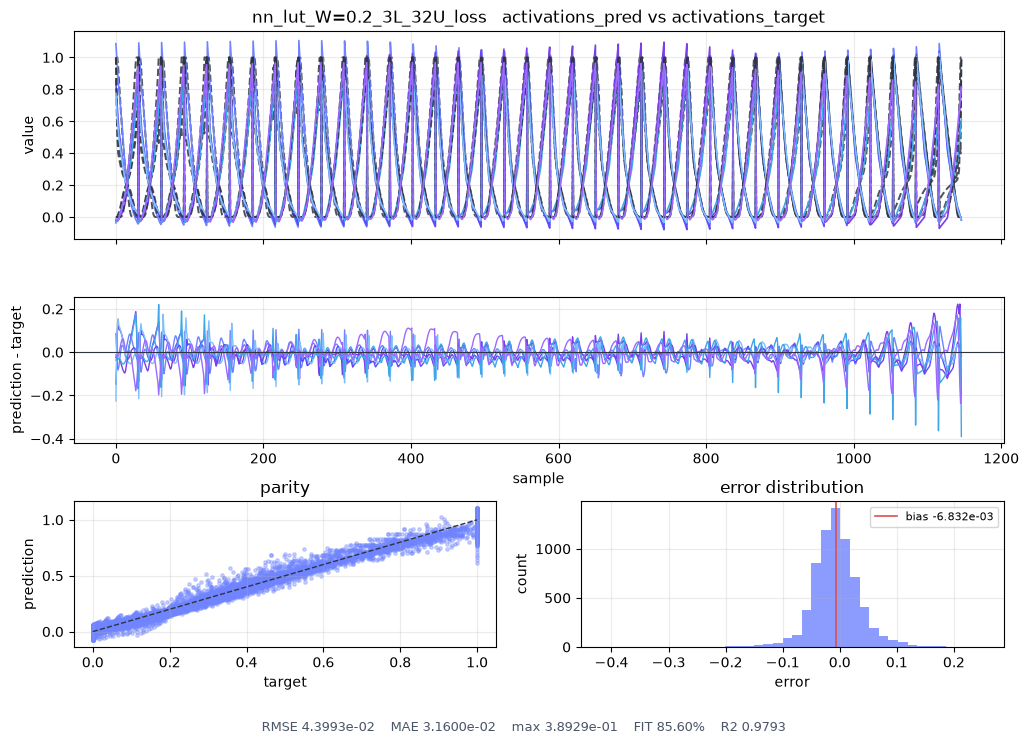

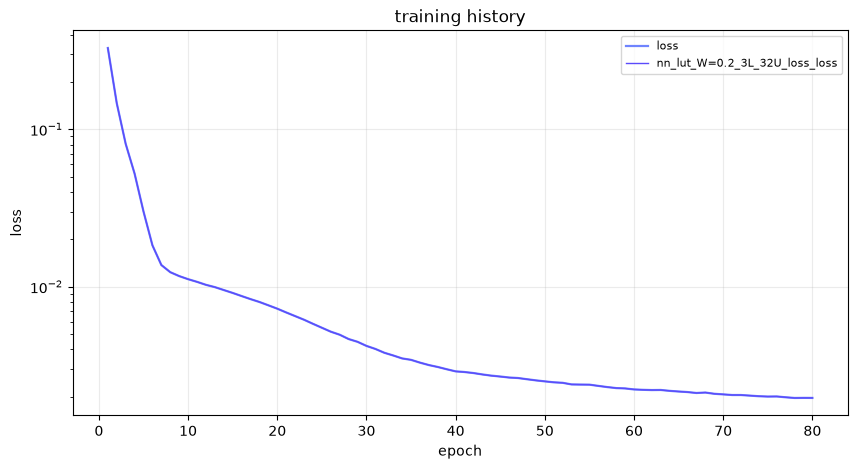

============================== nnodely Validation ==============================
Model:                        nn_lut_W=0.2_3L_32U
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
nn_lut_W=0.2_3L_32U_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   1.935422e-03
  RMSE                        4.399343e-02
  MAE                         3.159999e-02
  Max error                   3.892891e-01
  Bias (mean error)           -6.832368e-03
  Error std                   4.345964e-02
  NRMSE (% of range)          4.399 %
  FIT (% variance)            85.604 %
  R2                          0.979276
  Correlation                 0.989847
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/grid_search/nn_lut_W=0.2_3L_32U\nn_lut_W_0_2_3L_32U_nn_lut_W_0_2_3L_32U_loss.png
  Figure:                     mode

In [7]:
from src.nn_model_from_lut import NN_model_from_LUT

NUM_LAYERS_TO_TRY = [1, 2, 3]
NUM_UNITS_TO_TRY = [2, 4, 8, 16, 32]
ACTIVATION_MODE = "relu"

EPOCHS = 80
BATCH_SIZE = 64
LEARNING_RATE = 1e-3

PATH_GS = "models/W=0.2/grid_search"

trained_models = []

print(f"Grid Search: {len(NUM_LAYERS_TO_TRY) * len(NUM_UNITS_TO_TRY)} combinations...")
start_total = time.time()

for n_layers in NUM_LAYERS_TO_TRY:
    for n_units in NUM_UNITS_TO_TRY:
        
        print("\n" + "="*60)
        print(f"TRAINING: {n_layers} Layer, {n_units} Neurons")
        print("="*60)

        model_name = f"nn_lut_W=0.2_{n_layers}L_{n_units}U"
        start_train = time.time()

        # --- NN SETUP ---
        current_model = NN_model_from_LUT(model_name, my_lut)
        current_model.define_structure(n_layers, n_units, ACTIVATION_MODE)

        # --- NN TRAINING ---
        current_model.train(EPOCHS, BATCH_SIZE, LEARNING_RATE)
        train_time = time.time() - start_train
        print(f"Completed in {train_time:.1f} s.")

        # --- EXPORTS ---
        path_plot = f"{PATH_GS}/{model_name}"
        current_model.plot_results(path_plot)
        path_export = f"{PATH_GS}/{model_name}"
        current_model.export(path_export)

        # --- Save errors_heatmap ---
        #current_model.plot_error_heatmaps(save_path=f"{PATH_GS}/{model_name}")

        # --- Append in the list ---
        trained_models.append(current_model)


total_time = time.time() - start_total
print("\n" + "★"*60)
print(f"GRID SEARCH COMPLETED IN {total_time/60:.1f} MINUTES!")
print("★"*60)